In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
data = pd.read_csv(r"data\data.csv")


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [4]:
data = data.rename(columns={"Daytime/evening attendance\t":"Daytime/evening attendance"})

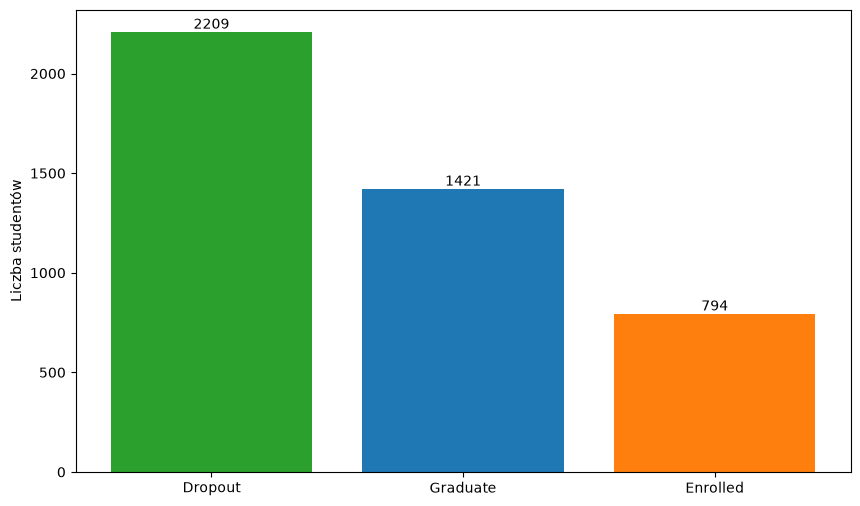

In [5]:
targets = data["Target"]
data = data.drop(columns=["Target"])

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
bar_colors = ['tab:green', 'tab:blue', 'tab:orange']

ax.bar(targets.unique(), height=targets.value_counts(), color=bar_colors)
ax.set_ylabel("Liczba studentów")
ax.bar_label(container=ax.containers[0], labels=targets.value_counts(), fontsize=10, color='black')

plt.show()

In [6]:
data.describe().round(2)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,...,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.18,18.67,1.73,8856.64,0.89,4.58,132.61,1.87,19.56,22.28,...,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,0.61,17.48,1.31,2063.57,0.31,10.22,13.19,6.91,15.60,15.34,...,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,1.00,1.00,0.00,33.00,0.00,1.00,95.00,1.00,1.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,1.00,1.00,9085.00,1.00,1.00,125.00,1.00,2.00,3.00,...,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,17.00,1.00,9238.00,1.00,1.00,133.10,1.00,19.00,19.00,...,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,1.00,39.00,2.00,9556.00,1.00,1.00,140.00,1.00,37.00,37.00,...,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,6.00,57.00,9.00,9991.00,1.00,43.00,190.00,109.00,44.00,44.00,...,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


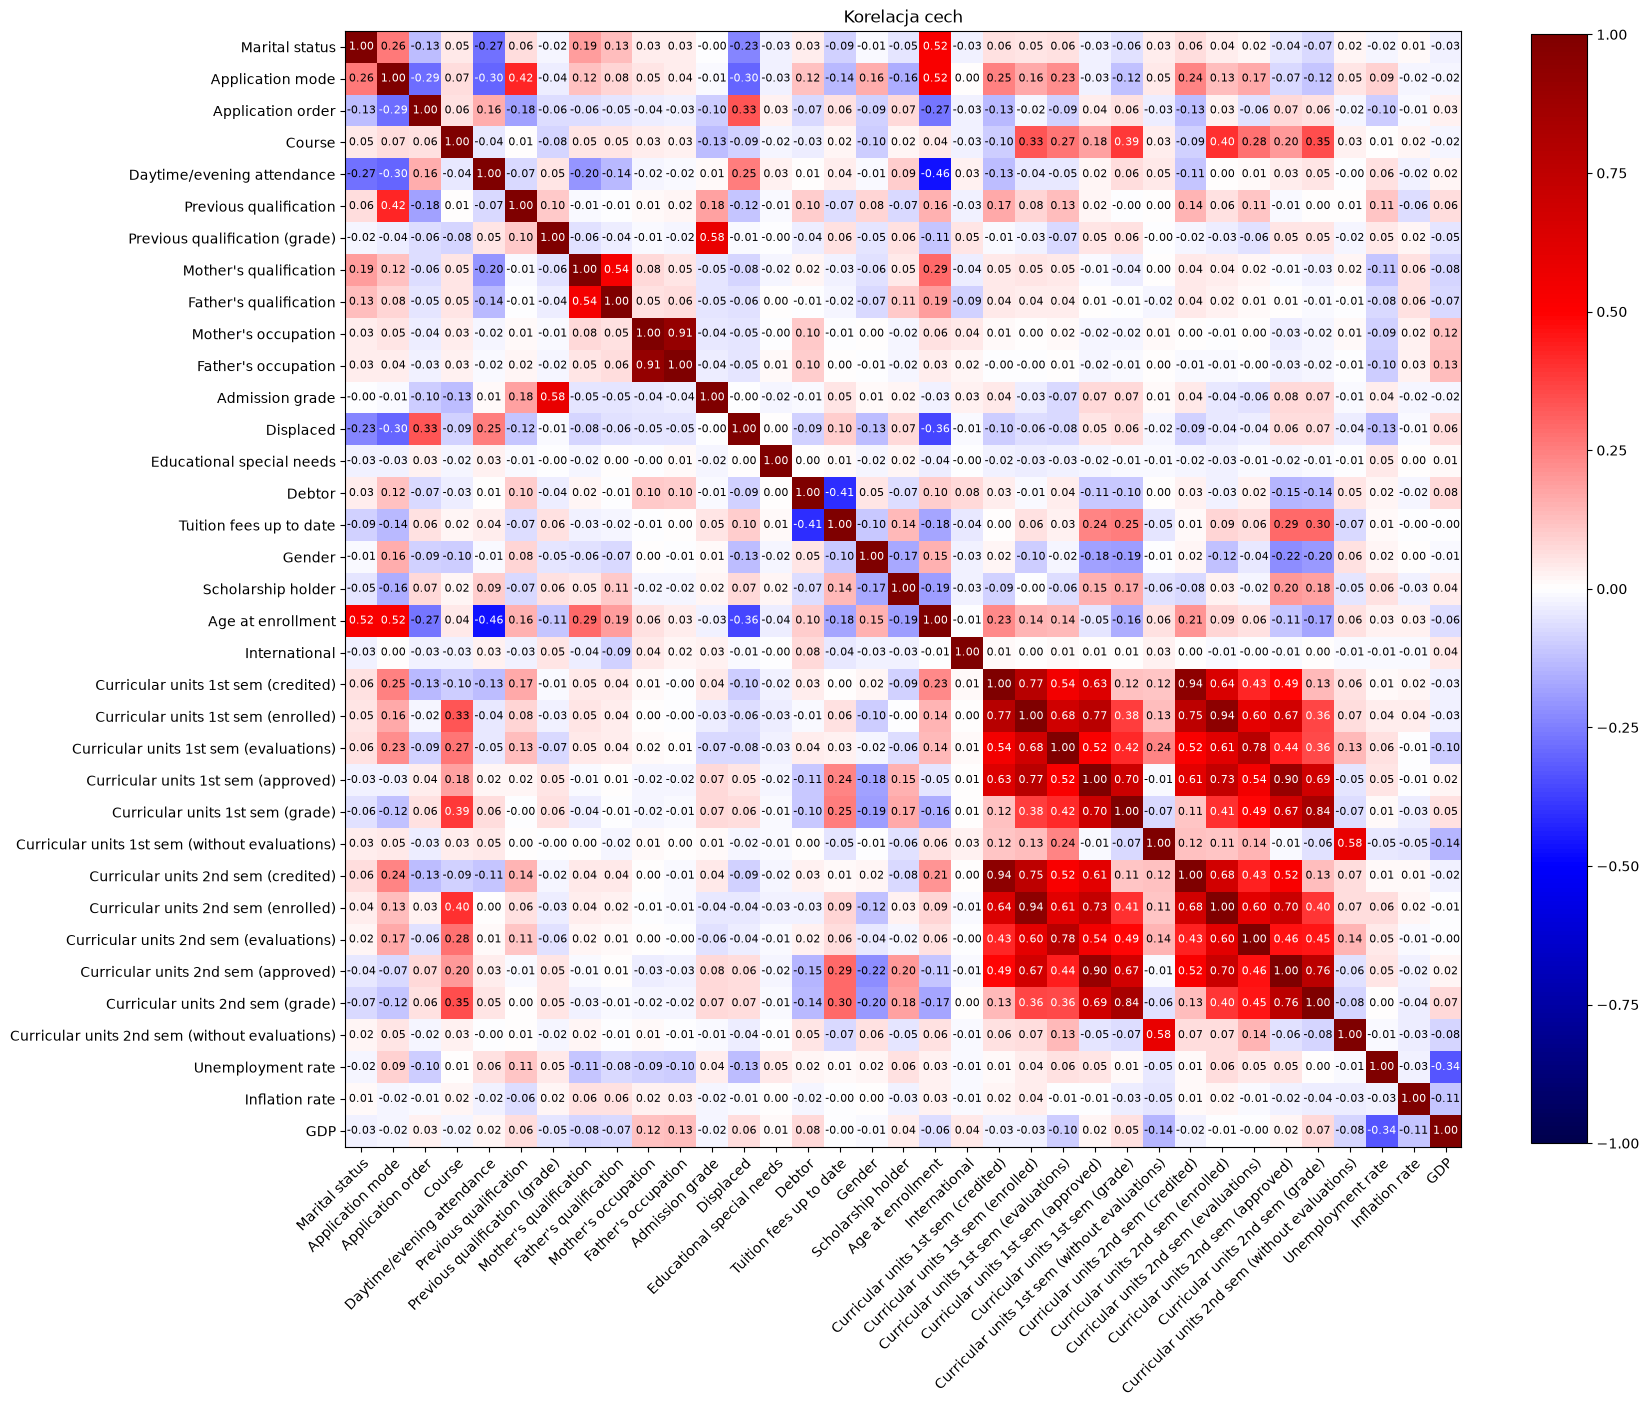

In [8]:

cor = data.corr()

fig, ax = plt.subplots(1, 1, figsize=(18, 18))
im = ax.imshow(cor, cmap="seismic", vmin=-1, vmax=1)

ax.set_xticks(range(cor.shape[0]), labels=data.columns.to_list(),
              rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticks(range(cor.shape[0]), labels=data.columns.to_list())

for i in range(cor.shape[0]):
    for j in range(cor.shape[1]):
        value = cor.iloc[i, j]
        rgba = im.cmap(im.norm(value))
        luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        color = "black" if luminance > 0.5 else "white"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color=color, fontsize=8)

fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Korelacja cech")

plt.show()

In [9]:
categorical = ["Marital status", "Application mode", "Course", "Daytime/evening attendance",
               "Previous qualification", "Mother's qualification", "Father's qualification",
               "Mother's occupation", "Father's occupation", "Displaced", "Educational special needs",
               "Debtor","Tuition fees up to date", "Gender", "Scholarship holder", "International"]

In [10]:
def one_hot_selected(df: pd.DataFrame, columns: list, drop_first: bool = False) -> pd.DataFrame:
    cols_to_encode = []

    for col in columns:
        unique_vals = set(df[col].dropna().unique())
        is_binary_01 = unique_vals.issubset({0, 1})

        if not is_binary_01:
            cols_to_encode.append(col)

    if not cols_to_encode:
        return df.copy()

    return pd.get_dummies(df, columns=cols_to_encode, drop_first=drop_first, dtype=int)



In [ ]:
transformed_data = one_hot_selected(data, categorical)
transformed_data["Target"] = targets

transformed_data.to_csv("data/transformed_data.csv")